# Student At-Risk Model Development

This version extends the original notebook with three changes:

1. **Feature selection is actually validated and wired in.** Instead of computing importances and never using them, the notebook now compares 10-fold CV performance *with* vs *without* the reduced feature set (as a proper pipeline step, refit inside every fold) and only keeps the selection if it doesn't meaningfully hurt performance.
2. **Threshold tuning no longer touches the test set.** The recall-targeted decision threshold is chosen from cross-validated out-of-fold predictions on the training set, then applied to the test set exactly once for the final report.
3. **Minor robustness fixes**: a named (picklable) function replaces the `lambda` inside `FunctionTransformer`, an assertion catches silently-unmapped target categories, and duplicate imports are removed.

> Note: `df_final.xlsx` isn't available in this environment, so cells haven't been executed here — run them locally against your data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone

# Data splitting and validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_predict,
    GridSearchCV
)

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve
)

# Feature selection (Methodology 3.4 - Feature Selection)
from sklearn.feature_selection import SelectFromModel

RANDOM_STATE = 42

## Load data

In [2]:
df = pd.read_excel('df_final.xlsx')  # Load your dataset here

## Target & feature setup

In [3]:
df = df.copy()

# TARGET VARIABLE
df["At_Risk_Status"] = df["At_Risk_Status"].map({
    "No": 0,
    "Yes": 1
})

# Guard against category values other than "No"/"Yes" silently becoming NaN
n_unmapped = df["At_Risk_Status"].isna().sum()
assert n_unmapped == 0, (
    f"{n_unmapped} rows in At_Risk_Status did not map to 0/1 - "
    "check for unexpected category values before proceeding."
)

# REMOVE IDENTIFIER
df = df.drop(columns=["Student_ID"], errors="ignore")

# DEFINE X AND y
target = "At_Risk_Status"

X = df.drop(columns=[target])
y = df[target]

# CHECK
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nData types:")
print(X.dtypes)

X shape: (330, 21)
y shape: (330,)

Target distribution:
At_Risk_Status
0    209
1    121
Name: count, dtype: int64

Data types:
Academic Year                                int64
APPLIED MECHANICS                            int64
COMPUTER SKILLS                              int64
CONSTRUCTION MATERIALS TECHNOLOGY            int64
ENGINEERING CHEMISTRY                        int64
ENGINEERING DRAWING 1                        int64
ENGINEERING MATHEMATICS 1                    int64
ENGINEERING PHYSICS                          int64
PROFESSIONAL AND TECHNICAL COMMUNICATION     int64
SURVEYING                                    int64
THEORY OF STRUCTURES                         int64
Gender                                      object
Language Name                               object
Ethnic Group Name                           object
Previous Activity Desc                      object
Matric Type                                 object
Age_At_Enrolment                             int64
Burs

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")
print(f"Training target distribution:")
print(y_train.value_counts(normalize=True))
print(f"\nTest target distribution:")
print(y_test.value_counts(normalize=True))

Training set: 231 samples
Test set: 99 samples
Training target distribution:
At_Risk_Status
0    0.632035
1    0.367965
Name: proportion, dtype: float64

Test target distribution:
At_Risk_Status
0    0.636364
1    0.363636
Name: proportion, dtype: float64


In [5]:
split_summary_df = pd.DataFrame({
    "Subset": ["Training", "Test"],
    "n": [X_train.shape[0], X_test.shape[0]],
    "Not At Risk": [
        f"{(y_train == 0).mean():.1%}",
        f"{(y_test == 0).mean():.1%}"
    ],
    "At Risk": [
        f"{(y_train == 1).mean():.1%}",
        f"{(y_test == 1).mean():.1%}"
    ]
})
split_summary_df

,Subset,n,Not At Risk,At Risk
0,Training,231,63.2%,36.8%
1,Test,99,63.6%,36.4%


In [6]:
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

In [7]:
print("categorical_features:", categorical_features)

print("numerical_features:", numerical_features)

categorical_features: ['Gender', 'Language Name', 'Ethnic Group Name', 'Previous Activity Desc', 'Matric Type', 'Bursary Type', 'Funded', 'Residence_Status']
numerical_features: ['Academic Year', 'APPLIED MECHANICS', 'COMPUTER SKILLS', 'CONSTRUCTION MATERIALS TECHNOLOGY', 'ENGINEERING CHEMISTRY', 'ENGINEERING DRAWING 1', 'ENGINEERING MATHEMATICS 1', 'ENGINEERING PHYSICS', 'PROFESSIONAL AND TECHNICAL COMMUNICATION', 'SURVEYING', 'THEORY OF STRUCTURES', 'Age_At_Enrolment', 'Secondary_School_Quintile']


In [8]:
def cast_to_str(X):
    """Cast every value to str after imputation.

    A named, module-level function (instead of the original lambda) so the
    fitted pipeline can be pickled / joblib-dumped for deployment. Some
    categorical columns (e.g. Secondary_School_Quintile) mix numeric and
    string values (e.g. 1, 2, "Not applicable"); casting to string after
    imputation avoids the "must be uniformly strings or numbers" error
    OneHotEncoder raises when it tries to sort mixed int/str categories.
    """
    return X.astype(str)


preprocessor = ColumnTransformer(
    transformers=[

        # Numerical variables
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numerical_features
        ),

        # Categorical variables
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("to_str", FunctionTransformer(cast_to_str, feature_names_out="one-to-one")),
                ("onehot", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ))
            ]),
            categorical_features
        )
    ]
)

## Feature Selection

In [9]:
# Feature Selection (Methodology 3.4)
# Fit the preprocessing pipeline on the training data only, then use a
# Random Forest's feature importances to see which features look most
# relevant. This is exploratory only at this stage - whether the reduced
# set is actually used downstream is decided empirically in the next
# section, not assumed here.

fs_preprocessor = clone(preprocessor)
X_train_fs = fs_preprocessor.fit_transform(X_train, y_train)
fs_feature_names = fs_preprocessor.get_feature_names_out()

fs_estimator = RandomForestClassifier(
    n_estimators=300, random_state=RANDOM_STATE, class_weight="balanced", n_jobs=-1
)
fs_estimator.fit(X_train_fs, y_train)

selector_preview = SelectFromModel(fs_estimator, threshold="median", prefit=True)
selected_mask = selector_preview.get_support()

feature_selection_df = pd.DataFrame({
    "Feature": fs_feature_names,
    "Importance": fs_estimator.feature_importances_,
    "Selected": selected_mask
}).sort_values("Importance", ascending=False)

print(f"Total features: {len(fs_feature_names)}")
print(f"Selected (above-median importance): {selected_mask.sum()}")
feature_selection_df.head(20)

Total features: 47
Selected (above-median importance): 24


,Feature,Importance,Selected
10,num__THEORY OF STRUCTURES,0.232958,True
1,num__APPLIED MECHANICS,0.095864,True
9,num__SURVEYING,0.095279,True
6,num__ENGINEERING MATHEMATICS 1,0.091287,True
7,num__ENGINEERING PHYSICS,0.072541,True
5,num__ENGINEERING DRAWING 1,0.071107,True
2,num__COMPUTER SKILLS,0.068906,True
4,num__ENGINEERING CHEMISTRY,0.065479,True
3,num__CONSTRUCTION MATERIALS TECHNOLOGY,0.037722,True
8,num__PROFESSIONAL AND TECHNICAL COMMUNICATION,0.029932,True


### Multicollinearity check (VIF)

The inferential Logistic Regression later hits a non-invertible Hessian
(quasi-separation) even after `drop="first"` encoding is suggested as a
fix. Severe multicollinearity among predictors is a common cause of
exactly this failure. This checks it directly on the same preprocessed
training matrix already built above for feature selection.

In [10]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_train_fs_df = pd.DataFrame(X_train_fs, columns=fs_feature_names)

vif_df = pd.DataFrame({
    "Feature": fs_feature_names,
    "VIF": [
        variance_inflation_factor(X_train_fs_df.values, i)
        for i in range(X_train_fs_df.shape[1])
    ]
}).sort_values("VIF", ascending=False)

n_high_vif = (vif_df["VIF"] > 10).sum()
print(f"Features with VIF > 10 (conventional 'high multicollinearity' threshold): "
      f"{n_high_vif} of {len(vif_df)}")

# NOTE: one-hot dummies from the SAME categorical column are expected to
# show elevated VIF against each other (they encode one variable between
# them, since no reference level was dropped) - that part is not a
# problem. Look for high VIF BETWEEN DIFFERENT underlying variables,
# which is the real multicollinearity signal.
vif_df.head(15)

Features with VIF > 10 (conventional 'high multicollinearity' threshold): 34 of 47


c:\Users\bayibayik\AppData\Local\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,Feature,VIF
23,cat__Language Name_TSHIVENDA,inf
35,cat__Previous Activity Desc_UNIVERSITY STUDENT,inf
26,cat__Ethnic Group Name_AFRICAN,inf
27,cat__Ethnic Group Name_COLOURED,inf
28,cat__Ethnic Group Name_WHITE,inf
29,cat__Previous Activity Desc_ENROLLED - FOREIGN...,inf
30,cat__Previous Activity Desc_GRADE12 LEARNER,inf
31,cat__Previous Activity Desc_LABOUR FORCE,inf
32,cat__Previous Activity Desc_OTHER,inf
33,cat__Previous Activity Desc_TECHNICAL COLLEGE ...,inf


### Does the selection actually help? Compare CV performance with vs. without it

`threshold="median"` mechanically keeps the top half of features by
importance - it is a candidate list, not proof that dropping the rest is a
good idea. The cell below wraps the selection as a real pipeline step
(`SelectFromModel`, refit inside every CV fold so there's no leakage) and
compares 10-fold CV metrics against the full-feature pipeline, for both
models. The reduced feature set is only adopted if it's within one standard
error of the full-feature model's CV ROC AUC (a standard "prefer the
simpler model unless it costs you something" rule) - otherwise all features
are kept.

In [11]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}


def make_pipeline(classifier, use_feature_selection):
    """Build a preprocessing (+ optional feature selection) + classifier
    pipeline. Feature selection, when included, is fit fresh inside every
    CV fold/GridSearchCV split - never prefit on the full training set -
    so comparisons below are leakage-free.
    """
    steps = [("preprocessor", clone(preprocessor))]
    if use_feature_selection:
        fs_clf = RandomForestClassifier(
            n_estimators=300, random_state=RANDOM_STATE,
            class_weight="balanced", n_jobs=-1
        )
        steps.append(("feature_selection", SelectFromModel(fs_clf, threshold="median")))
    steps.append(("classifier", classifier))
    return Pipeline(steps)


candidates = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        random_state=RANDOM_STATE, class_weight="balanced", n_jobs=-1
    ),
}

comparison_rows = []
for name, clf in candidates.items():
    for use_fs, label in [(False, "All features"), (True, "Selected features")]:
        pipe = make_pipeline(clf, use_fs)
        results = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
        row = {"Model": name, "Feature set": label}
        for metric in scoring:
            scores = results[f"test_{metric}"]
            row[f"{metric}_mean"] = scores.mean()
            row[f"{metric}_std"] = scores.std()
        comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows)
comparison_df[["Model", "Feature set", "roc_auc_mean", "roc_auc_std",
               "f1_mean", "accuracy_mean", "recall_mean", "precision_mean"]]

,Model,Feature set,roc_auc_mean,roc_auc_std,f1_mean,accuracy_mean,recall_mean,precision_mean
0,Logistic Regression,All features,0.933095,0.046759,0.815407,0.857246,0.848611,0.797361
1,Logistic Regression,Selected features,0.934630,0.044675,0.805981,0.848551,0.848611,0.782336
2,Random Forest,All features,0.957698,0.025134,0.825787,0.883333,0.775000,0.903532
3,Random Forest,Selected features,0.970754,0.017316,0.839484,0.892029,0.776389,0.922421


In [12]:
cv_table_df = comparison_df[[
    "Model", "Feature set", "roc_auc_mean", "roc_auc_std",
    "f1_mean", "accuracy_mean", "recall_mean", "precision_mean"
]].copy()

cv_table_df["ROC AUC (mean ± SD)"] = cv_table_df.apply(
    lambda r: f"{r['roc_auc_mean']:.3f} ± {r['roc_auc_std']:.3f}", axis=1
)
cv_table_df = cv_table_df.rename(columns={
    "Model": "Model", "Feature set": "Feature Set",
    "f1_mean": "F1", "accuracy_mean": "Accuracy",
    "recall_mean": "Recall", "precision_mean": "Precision"
})[["Model", "Feature Set", "ROC AUC (mean ± SD)", "F1", "Accuracy", "Recall", "Precision"]]

cv_table_df = cv_table_df.round(3)
cv_table_df

,Model,Feature Set,ROC AUC (mean ± SD),F1,Accuracy,Recall,Precision
0,Logistic Regression,All features,0.933 ± 0.047,0.815,0.857,0.849,0.797
1,Logistic Regression,Selected features,0.935 ± 0.045,0.806,0.849,0.849,0.782
2,Random Forest,All features,0.958 ± 0.025,0.826,0.883,0.775,0.904
3,Random Forest,Selected features,0.971 ± 0.017,0.839,0.892,0.776,0.922


In [13]:
TOLERANCE_SE = 1.0  # keep the simpler (selected-feature) model if its CV
                     # ROC AUC is within this many standard errors of the
                     # full-feature model's CV ROC AUC

use_selected_features = {}

for name in candidates:
    subset = comparison_df[comparison_df["Model"] == name].set_index("Feature set")
    full_auc = subset.loc["All features", "roc_auc_mean"]
    full_se = subset.loc["All features", "roc_auc_std"]
    sel_auc = subset.loc["Selected features", "roc_auc_mean"]

    keep_selected = sel_auc >= (full_auc - TOLERANCE_SE * full_se)
    use_selected_features[name] = keep_selected

    verdict = "USE selected features" if keep_selected else "KEEP all features"
    print(f"{name:22} full ROC AUC={full_auc:.4f}  selected ROC AUC={sel_auc:.4f}  -> {verdict}")

Logistic Regression    full ROC AUC=0.9331  selected ROC AUC=0.9346  -> USE selected features
Random Forest          full ROC AUC=0.9577  selected ROC AUC=0.9708  -> USE selected features


### Feature-space helpers

Since whether feature selection is used now depends on the comparison
above (rather than being hard-coded), the helpers below read feature
names and transformed matrices directly off a *fitted* pipeline, whether
or not it has a `feature_selection` step. Every downstream cell (coefficient
plots, RF importances, the decision tree plot, SHAP, and the statsmodels
model) uses these instead of assuming the preprocessor's raw output.

In [14]:
def get_final_feature_names(fitted_pipeline):
    """Feature names entering the classifier step (after preprocessing
    and, if present, feature selection)."""
    names = fitted_pipeline.named_steps["preprocessor"].get_feature_names_out()
    if "feature_selection" in fitted_pipeline.named_steps:
        names = fitted_pipeline.named_steps["feature_selection"].get_feature_names_out(names)
    return names


def transform_up_to_classifier(fitted_pipeline, X):
    """Transform X through every step except the final classifier."""
    Xt = fitted_pipeline.named_steps["preprocessor"].transform(X)
    if "feature_selection" in fitted_pipeline.named_steps:
        Xt = fitted_pipeline.named_steps["feature_selection"].transform(Xt)
    return Xt

## Testing Logistic Regression, Random Forest

### Logistic Regression

In [15]:
# LOGISTIC REGRESSION
logistic_model = make_pipeline(
    LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    use_feature_selection=use_selected_features["Logistic Regression"]
)

### Logistic Regression — hyperparameter tuning

Random Forest below is tuned via `GridSearchCV`; until now Logistic
Regression used sklearn's default `C=1.0` with no search at all, which
made the two models' comparison uneven. This searches the
regularisation strength the same way Random Forest's hyperparameters
are searched, so both models get a fair shot at their best configuration.

In [16]:
logistic_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__penalty": ["l2"],  # lbfgs (the default solver) only supports l2/none
}

logistic_grid_search = GridSearchCV(
    logistic_model,
    logistic_param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

logistic_grid_search.fit(X_train, y_train)

print("Best Logistic Regression params:", logistic_grid_search.best_params_)
print(f"Best CV ROC AUC: {logistic_grid_search.best_score_:.4f}")

# Carry the tuned pipeline forward - every cell below (CV report, final
# fit, coefficients, confusion matrix, etc.) keeps working unchanged.
logistic_model = logistic_grid_search.best_estimator_

Best Logistic Regression params: {'classifier__C': 1, 'classifier__penalty': 'l2'}
Best CV ROC AUC: 0.9346


In [17]:
# LOGISTIC REGRESSION - 10-FOLD CV

logistic_cv = cross_validate(
    estimator=logistic_model,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("\nLOGISTIC REGRESSION - 10-FOLD CV")

for metric in scoring:

    scores = logistic_cv[f"test_{metric}"]

    print(
        f"{metric.capitalize():12}: "
        f"{scores.mean():.4f} "
        f"(+/- {scores.std():.4f})"
    )


LOGISTIC REGRESSION - 10-FOLD CV
Accuracy    : 0.8486 (+/- 0.0589)
Precision   : 0.7823 (+/- 0.0994)
Recall      : 0.8486 (+/- 0.1044)
F1          : 0.8060 (+/- 0.0664)
Roc_auc     : 0.9346 (+/- 0.0447)


In [18]:
# LOGISTIC REGRESSION - FINAL MODEL

logistic_model.fit(
    X_train,
    y_train
)

logistic_pred = logistic_model.predict(X_test)

logistic_prob = logistic_model.predict_proba(
    X_test
)[:, 1]

In [19]:
print("\nLOGISTIC REGRESSION - TEST SET")

print(classification_report(
    y_test,
    logistic_pred,
    target_names=["Not At Risk", "At Risk"]
))

print("Accuracy:",
      accuracy_score(y_test, logistic_pred))

print("Precision:",
      precision_score(y_test, logistic_pred))

print("Recall:",
      recall_score(y_test, logistic_pred))

print("F1:",
      f1_score(y_test, logistic_pred))

print("ROC AUC:",
      roc_auc_score(y_test, logistic_prob))


LOGISTIC REGRESSION - TEST SET
              precision    recall  f1-score   support

 Not At Risk       0.83      0.87      0.85        63
     At Risk       0.76      0.69      0.72        36

    accuracy                           0.81        99
   macro avg       0.80      0.78      0.79        99
weighted avg       0.81      0.81      0.81        99

Accuracy: 0.8080808080808081
Precision: 0.7575757575757576
Recall: 0.6944444444444444
F1: 0.7246376811594203
ROC AUC: 0.9153439153439153


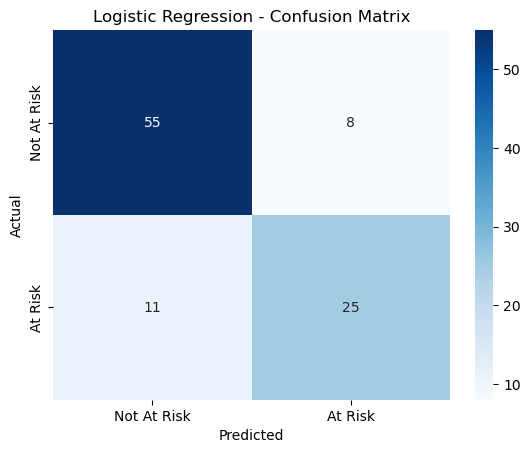

In [20]:
lr_cm = confusion_matrix(y_test, logistic_pred)

sns.heatmap(lr_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not At Risk", "At Risk"],
            yticklabels=["Not At Risk", "At Risk"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [21]:
import statsmodels.api as sm

# PREPARE DATA FOR STATSMODELS LOGISTIC REGRESSION
#
# This inferential model is fit on the FULL feature set with drop="first"
# one-hot encoding, independent of whichever feature subset the earlier CV
# comparison chose for the predictive (sklearn) models. Two reasons:
#   1. SelectFromModel selects columns *after* one-hot encoding, not raw
#      columns, so mapping the ML-selected feature list onto a
#      drop="first" encoding is ambiguous - not worth trying to keep in
#      sync.
#   2. drop="first" avoids the "dummy variable trap": without it, every
#      categorical column's one-hot dummies sum to 1 for every row, which
#      is an exact linear dependency with the intercept and can make the
#      Hessian singular on its own - separate from, and on top of, any
#      quasi-separation in the data.

sm_preprocessor = clone(preprocessor)
sm_preprocessor.set_params(cat__onehot=OneHotEncoder(
    drop="first", handle_unknown="ignore", sparse_output=False
))

X_train_sm = sm_preprocessor.fit_transform(X_train, y_train)
sm_feature_names = sm_preprocessor.get_feature_names_out()

# Convert to DataFrame
X_train_sm_df = pd.DataFrame(
    X_train_sm,
    columns=sm_feature_names
)

# Make sure everything is numeric
X_train_sm_df = X_train_sm_df.apply(pd.to_numeric, errors="coerce")

# Replace infinite values
X_train_sm_df = X_train_sm_df.replace([np.inf, -np.inf], np.nan)

# Remove columns containing NaN
X_train_sm_df = X_train_sm_df.dropna(axis=1)

# REMOVE CONSTANT COLUMNS
constant_cols = [
    col for col in X_train_sm_df.columns
    if X_train_sm_df[col].nunique() <= 1
]

if constant_cols:
    print("Removing constant columns:")
    print(constant_cols)

    X_train_sm_df = X_train_sm_df.drop(columns=constant_cols)

# REMOVE DUPLICATE COLUMNS
duplicate_cols = X_train_sm_df.T.duplicated()

if duplicate_cols.any():
    duplicate_names = X_train_sm_df.columns[duplicate_cols].tolist()

    print("\nRemoving duplicate columns:")
    print(duplicate_names)

    X_train_sm_df = X_train_sm_df.loc[:, ~duplicate_cols]

# CHECK FOR PERFECT MULTICOLLINEARITY
X_train_sm_df = sm.add_constant(
    X_train_sm_df,
    has_constant="add"
)

# Target
y_train_sm = pd.Series(y_train).reset_index(drop=True)

# Make sure X and y have the same number of rows
X_train_sm_df = X_train_sm_df.reset_index(drop=True)

print("\nFinal X shape:", X_train_sm_df.shape)
print("Final y shape:", y_train_sm.shape)

# FIT LOGISTIC REGRESSION
#
# sm.Logit(...).fit() can report converged=True while still failing to
# invert the Hessian (HessianInversionWarning) under quasi/complete
# separation - a small number of rows a predictor (or combination of
# predictors) predicts perfectly. That failure surfaces as a WARNING, not
# an exception, so the original try/except (which only caught
# np.linalg.LinAlgError) let NaN standard errors and p-values through
# silently. This checks the fitted result directly instead.
logit_result = sm.Logit(
    y_train_sm,
    X_train_sm_df
).fit(
    method="lbfgs",
    maxiter=1000,
    disp=0
)

se_unusable = logit_result.bse.isna().any() or np.isinf(logit_result.bse).any()

if se_unusable:
    print("\nStandard errors are NaN/inf - quasi-separation is still present")
    print("even after fixing the dummy-variable trap (drop='first'). Falling")
    print("back to L1-regularized logistic regression for stable, finite")
    print("coefficients. Note statsmodels' fit_regularized() does not provide")
    print("p-values/CIs either way, so read this fit for DIRECTION only, not")
    print("for significance testing.")

    logit_result = sm.Logit(
        y_train_sm,
        X_train_sm_df
    ).fit_regularized(
        method="l1",
        alpha=0.01,
        maxiter=2000,
        disp=0
    )

print(logit_result.summary())


Final X shape: (231, 40)
Final y shape: (231,)
                           Logit Regression Results                           
Dep. Variable:         At_Risk_Status   No. Observations:                  231
Model:                          Logit   Df Residuals:                      192
Method:                           MLE   Df Model:                           38
Date:                Sat, 24 Oct 2026   Pseudo R-squ.:                  0.7219
Time:                        10:45:41   Log-Likelihood:                -42.264
converged:                       True   LL-Null:                       -151.97
Covariance Type:            nonrobust   LLR p-value:                 2.246e-27
                                                           coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------
const                                                  -14.5097   6.79e+06  -2

### Random Forest

In [22]:
# RANDOM FOREST - grid search (10-fold CV) + final model
rf_model = make_pipeline(
    RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced", n_jobs=-1),
    use_feature_selection=use_selected_features["Random Forest"]
)

param_grid = {
    "classifier__n_estimators": [100, 300, 500],
    "classifier__max_depth": [None, 5, 10, 20],
    "classifier__min_samples_leaf": [1, 2, 5]
}

grid_search = GridSearchCV(
    rf_model,
    param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

rf_model = grid_search.best_estimator_
print("Best RF params:", grid_search.best_params_)

pred = rf_model.predict(X_test)
prob = rf_model.predict_proba(X_test)[:, 1]

print("\nRANDOM FOREST - TEST SET")
print(classification_report(y_test, pred, target_names=["Not At Risk", "At Risk"]))

print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred))
print("Recall:", recall_score(y_test, pred))
print("F1:", f1_score(y_test, pred))
print("ROC AUC:", roc_auc_score(y_test, prob))

# 10-FOLD CROSS VALIDATION (on the training set, using the tuned model)
cv_results = cross_validate(
    estimator=rf_model,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("\nRandom Forest (10-Fold CV)")
for metric in scoring.keys():
    scores = cv_results[f"test_{metric}"]
    print(f"{metric.capitalize():10}: {scores.mean():.4f} (+/- {scores.std():.4f})")

Best RF params: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 300}

RANDOM FOREST - TEST SET
              precision    recall  f1-score   support

 Not At Risk       0.85      0.98      0.91        63
     At Risk       0.96      0.69      0.81        36

    accuracy                           0.88        99
   macro avg       0.91      0.84      0.86        99
weighted avg       0.89      0.88      0.87        99

Accuracy: 0.8787878787878788
Precision: 0.9615384615384616
Recall: 0.6944444444444444
F1: 0.8064516129032258
ROC AUC: 0.9708994708994709

Random Forest (10-Fold CV)
Accuracy  : 0.9007 (+/- 0.0576)
Precision : 0.9224 (+/- 0.0813)
Recall    : 0.8000 (+/- 0.1013)
F1        : 0.8542 (+/- 0.0813)
Roc_auc   : 0.9733 (+/- 0.0163)


In [23]:
test_perf_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC AUC"],
    "Logistic Regression": [
        accuracy_score(y_test, logistic_pred),
        precision_score(y_test, logistic_pred),
        recall_score(y_test, logistic_pred),
        f1_score(y_test, logistic_pred),
        roc_auc_score(y_test, logistic_prob)
    ],
    "Random Forest": [
        accuracy_score(y_test, pred),
        precision_score(y_test, pred),
        recall_score(y_test, pred),
        f1_score(y_test, pred),
        roc_auc_score(y_test, prob)
    ]
}).round(3)

test_perf_df

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.808,0.879
1,Precision,0.758,0.962
2,Recall,0.694,0.694
3,F1-score,0.725,0.806
4,ROC AUC,0.915,0.971


### Bootstrap confidence intervals for the test-set metrics

With only 99 students in the test set, a single number like "ROC AUC =
0.973" hides how much that estimate could move with a slightly
different sample of students. This resamples the test set (with
replacement) 2,000 times and recomputes each metric, giving a 95%
confidence interval around every point estimate instead.

In [24]:
from IPython.display import display

N_BOOTSTRAPS = 2000
rng = np.random.RandomState(RANDOM_STATE)


def bootstrap_ci(y_true, y_pred, y_prob, n_boot=N_BOOTSTRAPS):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_prob = np.asarray(y_prob)
    n = len(y_true)

    boot_scores = {"accuracy": [], "precision": [], "recall": [], "f1": [], "roc_auc": []}

    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        yt, yp, ypr = y_true[idx], y_pred[idx], y_prob[idx]

        # Skip resamples with only one class present - ROC AUC (and some
        # other metrics) are undefined when that happens.
        if len(np.unique(yt)) < 2:
            continue

        boot_scores["accuracy"].append(accuracy_score(yt, yp))
        boot_scores["precision"].append(precision_score(yt, yp, zero_division=0))
        boot_scores["recall"].append(recall_score(yt, yp, zero_division=0))
        boot_scores["f1"].append(f1_score(yt, yp, zero_division=0))
        boot_scores["roc_auc"].append(roc_auc_score(yt, ypr))

    rows = []
    for metric, scores in boot_scores.items():
        scores = np.array(scores)
        rows.append({
            "Metric": metric,
            "Point estimate": scores.mean(),
            "95% CI Lower": np.percentile(scores, 2.5),
            "95% CI Upper": np.percentile(scores, 97.5)
        })
    return pd.DataFrame(rows).round(3)


print("Logistic Regression \u2014 bootstrap 95% CIs (test set)")
lr_ci_df = bootstrap_ci(y_test, logistic_pred, logistic_prob)
display(lr_ci_df)

print("\nRandom Forest \u2014 bootstrap 95% CIs (test set)")
rf_ci_df = bootstrap_ci(y_test, pred, prob)
display(rf_ci_df)

Logistic Regression — bootstrap 95% CIs (test set)


,Metric,Point estimate,95% CI Lower,95% CI Upper
0,accuracy,0.810,0.737,0.889
1,precision,0.761,0.613,0.900
2,recall,0.698,0.543,0.844
3,f1,0.725,0.604,0.836
4,roc_auc,0.917,0.865,0.962



Random Forest — bootstrap 95% CIs (test set)


,Metric,Point estimate,95% CI Lower,95% CI Upper
0,accuracy,0.878,0.808,0.939
1,precision,0.960,0.871,1.000
2,recall,0.692,0.538,0.838
3,f1,0.802,0.681,0.901
4,roc_auc,0.970,0.938,0.993


### ROC curves — both models on one chart

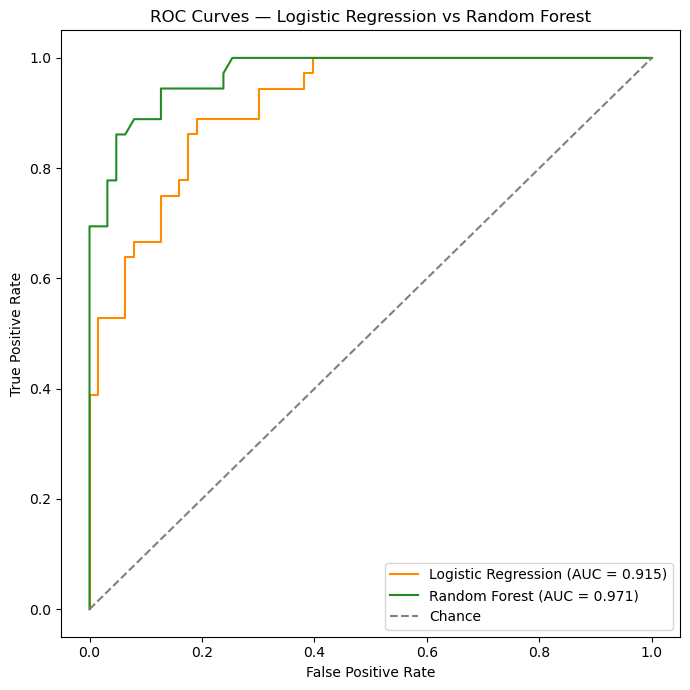

In [25]:
from sklearn.metrics import roc_curve

fpr_lr, tpr_lr, _ = roc_curve(y_test, logistic_prob)
fpr_rf, tpr_rf, _ = roc_curve(y_test, prob)

plt.figure(figsize=(7, 7))
plt.plot(fpr_lr, tpr_lr, color="darkorange",
         label=f"Logistic Regression (AUC = {roc_auc_score(y_test, logistic_prob):.3f})")
plt.plot(fpr_rf, tpr_rf, color="forestgreen",
         label=f"Random Forest (AUC = {roc_auc_score(y_test, prob):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Chance")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Logistic Regression vs Random Forest")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

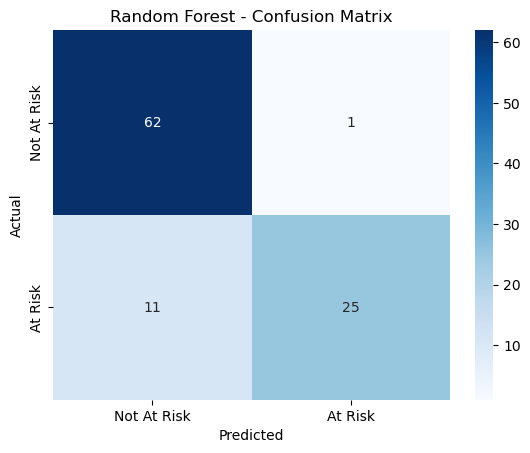

In [26]:
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not At Risk", "At Risk"],
            yticklabels=["Not At Risk", "At Risk"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [27]:
# Get feature names after preprocessing (+ feature selection, if adopted)
feature_names = get_final_feature_names(rf_model)

# Get feature importances
importances = rf_model.named_steps["classifier"].feature_importances_

# Create table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display Top 20
importance_df.head(20)

,Feature,Importance
10,num__THEORY OF STRUCTURES,0.267147
1,num__APPLIED MECHANICS,0.106081
6,num__ENGINEERING MATHEMATICS 1,0.094386
9,num__SURVEYING,0.084742
5,num__ENGINEERING DRAWING 1,0.073577
4,num__ENGINEERING CHEMISTRY,0.072676
7,num__ENGINEERING PHYSICS,0.070392
2,num__COMPUTER SKILLS,0.066512
3,num__CONSTRUCTION MATERIALS TECHNOLOGY,0.032978
8,num__PROFESSIONAL AND TECHNICAL COMMUNICATION,0.031454


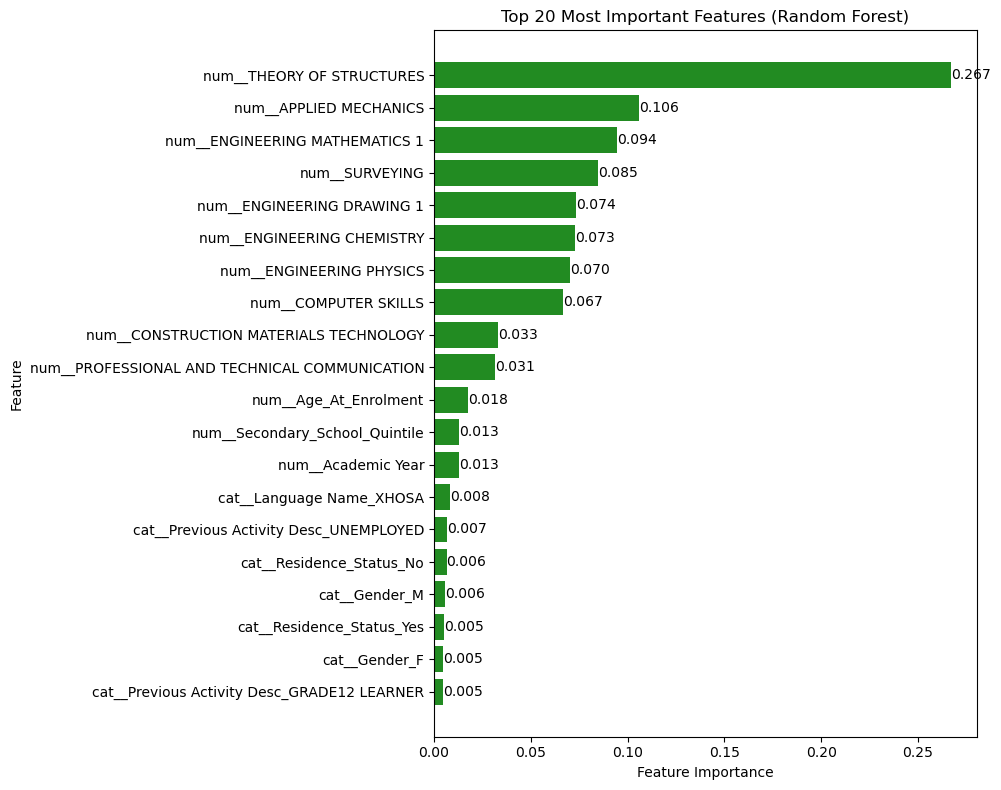

In [28]:
top20 = importance_df.head(20)

plt.figure(figsize=(10,8))

plt.barh(
    top20["Feature"],
    top20["Importance"],
    color="forestgreen"
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 Most Important Features (Random Forest)")

plt.gca().invert_yaxis()

# Add values
for i, value in enumerate(top20["Importance"]):
    plt.text(value, i, f"{value:.3f}", va="center")

plt.tight_layout()
plt.show()

### Feature importance, aggregated back to the original variables

The chart above shows one bar per one-hot-encoded dummy (e.g. a separate bar for
each category of `Bursary_Type`), which gets noisy for a mixed categorical/
numerical dataset like this one. The cell below sums each dummy's importance
back onto its original column, so the chart reads as "how much does
`Bursary_Type` matter" rather than "how much does `Bursary_Type_NSFAS`
matter" - matching the aggregated Random Forest importance view from the
original project report.

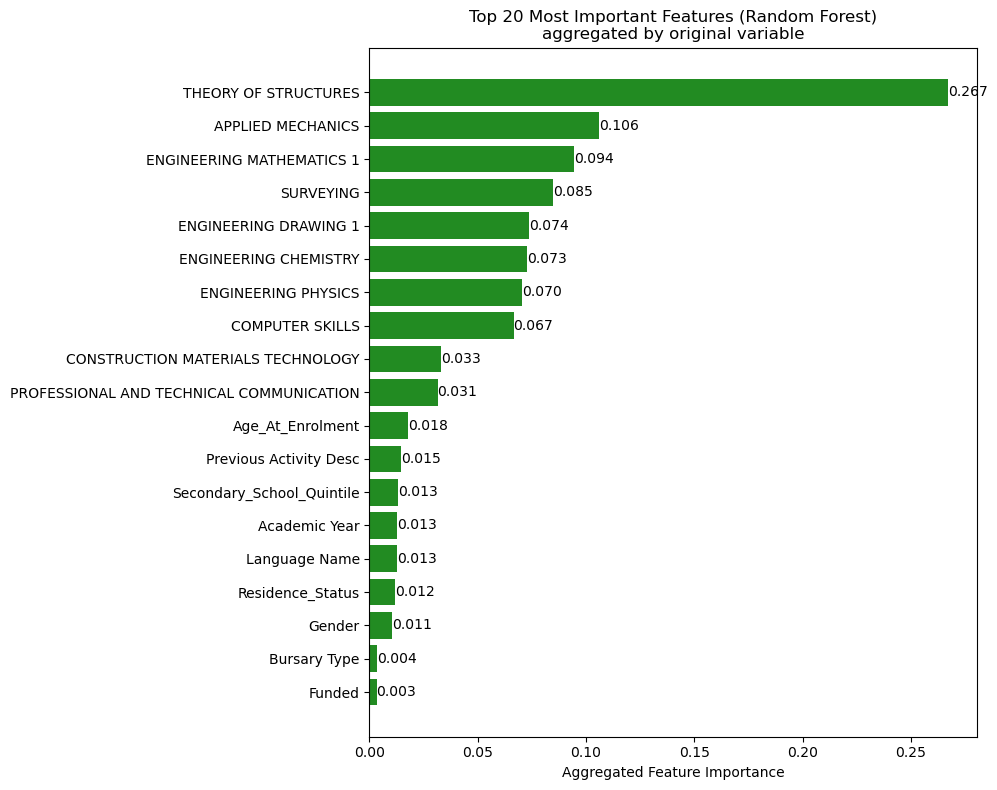

,Feature,Importance
10,THEORY OF STRUCTURES,0.267147
1,APPLIED MECHANICS,0.106081
6,ENGINEERING MATHEMATICS 1,0.094386
9,SURVEYING,0.084742
5,ENGINEERING DRAWING 1,0.073577
4,ENGINEERING CHEMISTRY,0.072676
7,ENGINEERING PHYSICS,0.070392
2,COMPUTER SKILLS,0.066512
3,CONSTRUCTION MATERIALS TECHNOLOGY,0.032978
8,PROFESSIONAL AND TECHNICAL COMMUNICATION,0.031454


In [29]:
# Aggregate one-hot-encoded importances back to their original variable
# (e.g. "cat__Bursary_Type_NSFAS" + "cat__Bursary_Type_Other" -> "Bursary_Type")
# so the chart shows how much each ORIGINAL feature matters, not each dummy.

feature_names = get_final_feature_names(rf_model)
importances = rf_model.named_steps["classifier"].feature_importances_

def base_feature_name(name):
    name = name.split("__", 1)[-1]          # strip the "num__"/"cat__" prefix
    for col in categorical_features:
        if name.startswith(col + "_"):      # strip the one-hot category suffix
            return col
    return name

agg = {}
for feat, imp in zip(feature_names, importances):
    base = base_feature_name(feat)
    agg[base] = agg.get(base, 0) + imp

importance_agg_df = pd.DataFrame(
    {"Feature": list(agg.keys()), "Importance": list(agg.values())}
).sort_values("Importance", ascending=False)

top20_agg = importance_agg_df.head(20)

plt.figure(figsize=(10, 8))
plt.barh(top20_agg["Feature"], top20_agg["Importance"], color="forestgreen")
plt.xlabel("Aggregated Feature Importance")
plt.title("Top 20 Most Important Features (Random Forest)\naggregated by original variable")
plt.gca().invert_yaxis()

for i, value in enumerate(top20_agg["Importance"]):
    plt.text(value, i, f"{value:.3f}", va="center")

plt.tight_layout()
plt.show()

importance_agg_df.head(20)

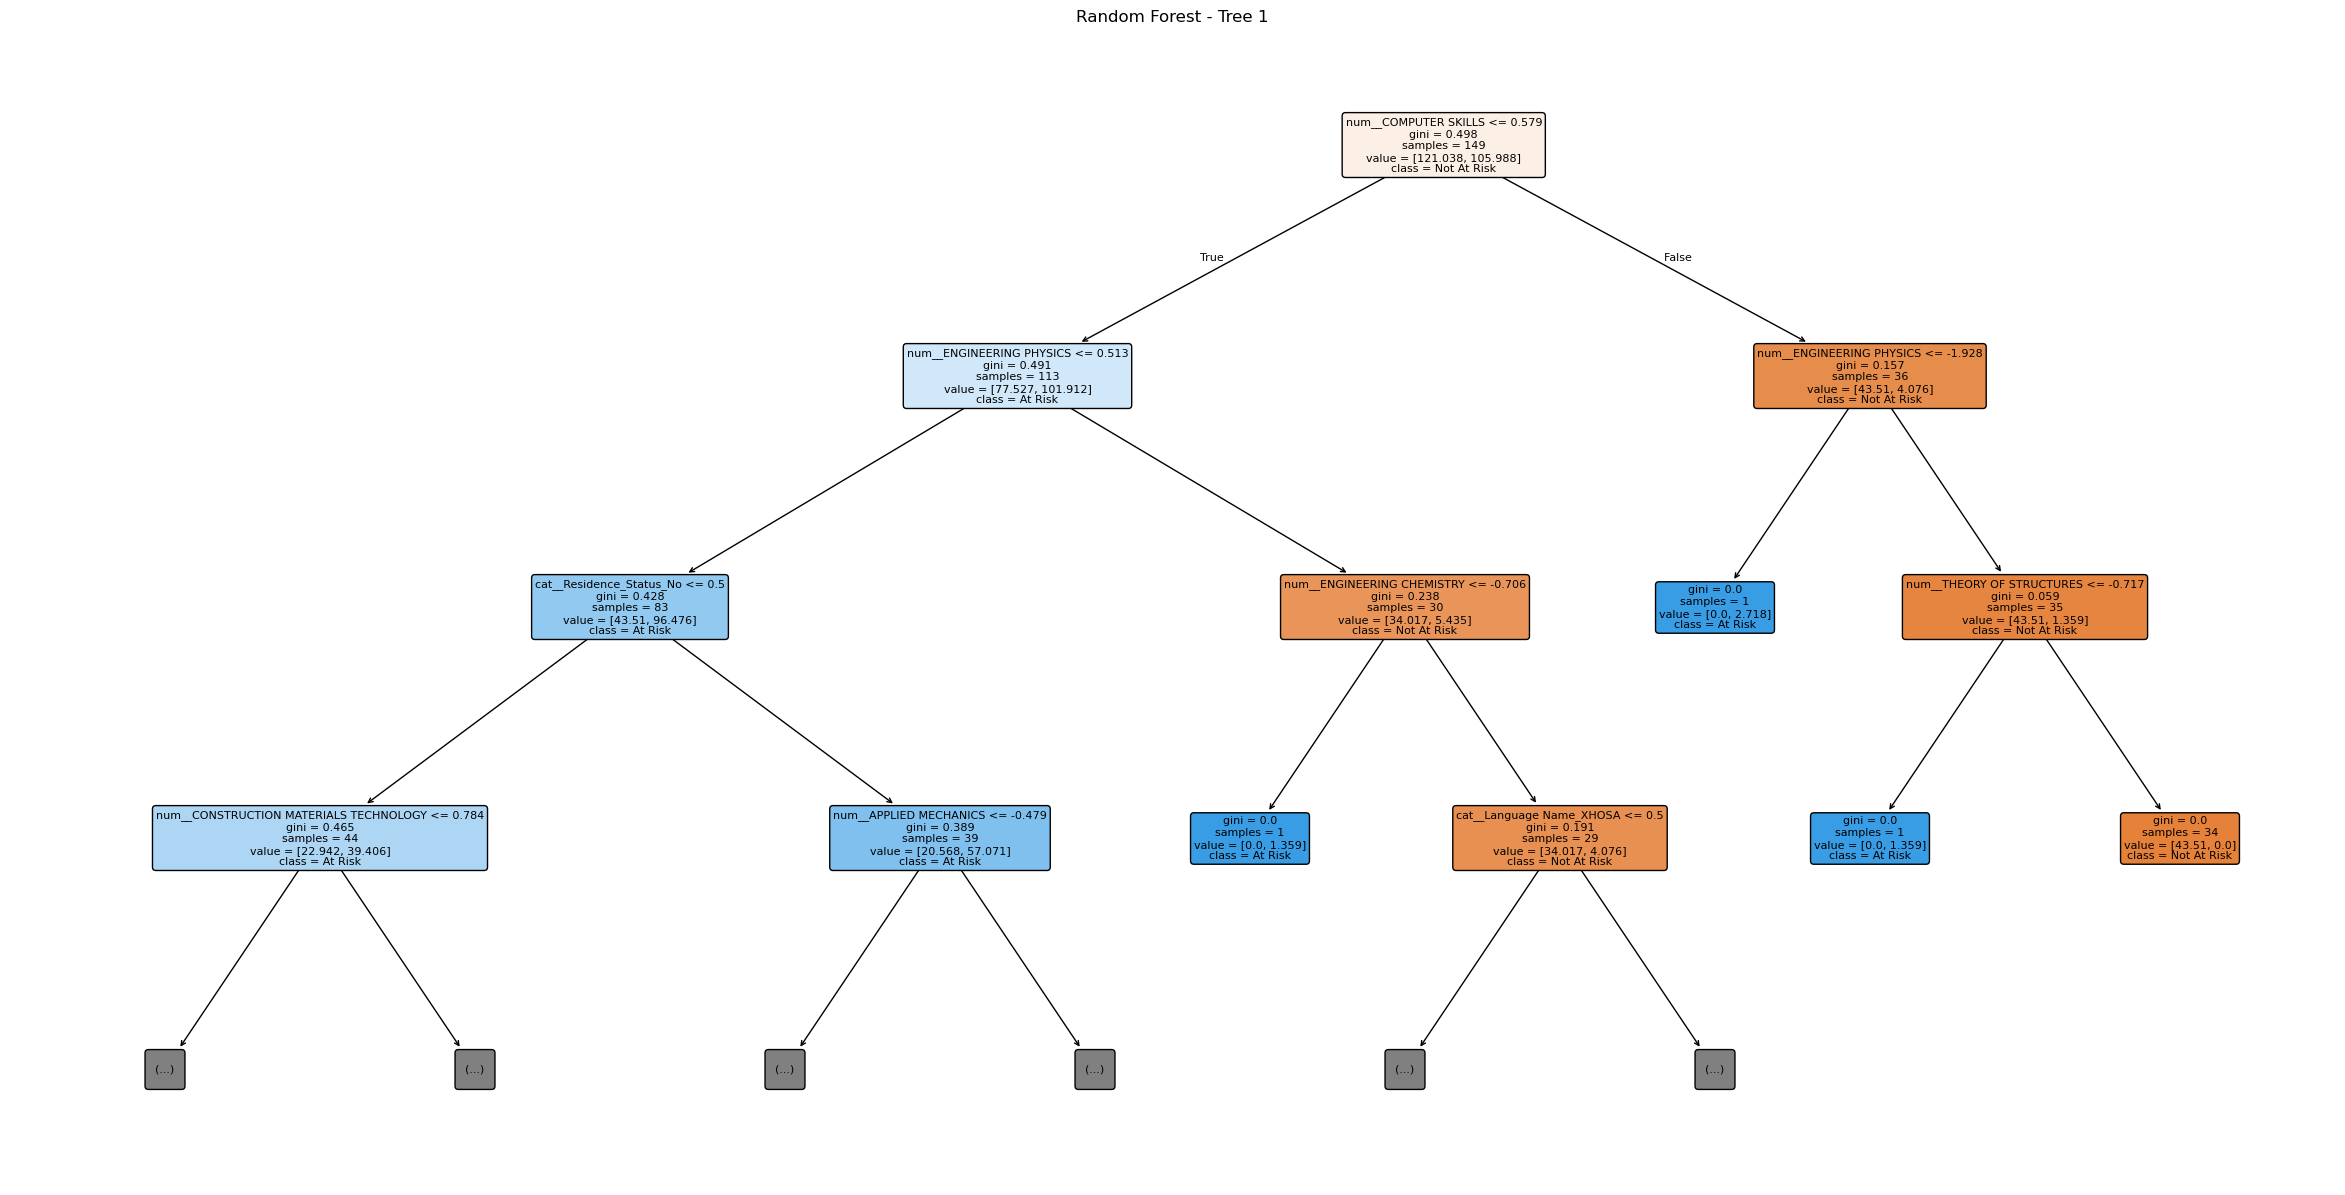

In [30]:
from sklearn.tree import plot_tree

# Extract one tree
tree = rf_model.named_steps["classifier"].estimators_[0]

plt.figure(figsize=(30,15))

plot_tree(
    tree,
    feature_names=feature_names,
    class_names=["Not At Risk", "At Risk"],
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3      # keeps the tree readable
)

plt.title("Random Forest - Tree 1")
plt.show()

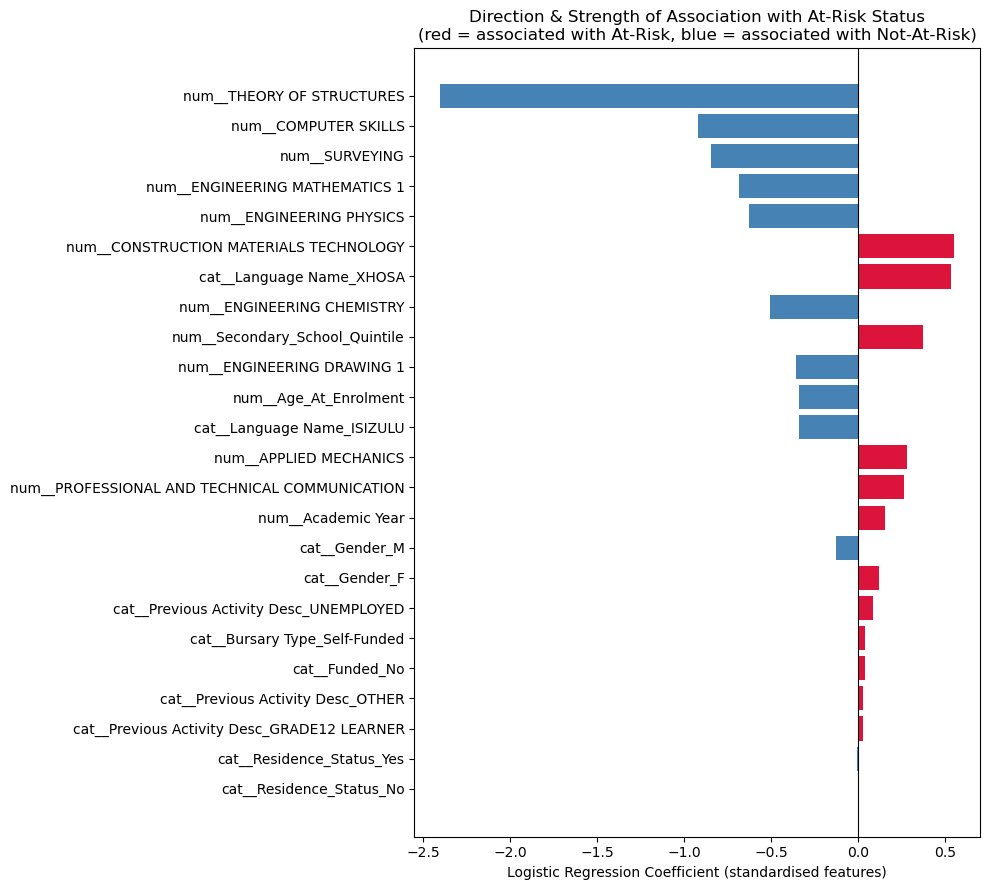

,Feature,Coefficient,Odds Ratio,Direction
10,num__THEORY OF STRUCTURES,-2.403015,0.090445,Associated with Not-At-Risk
2,num__COMPUTER SKILLS,-0.921142,0.398064,Associated with Not-At-Risk
9,num__SURVEYING,-0.849083,0.427807,Associated with Not-At-Risk
6,num__ENGINEERING MATHEMATICS 1,-0.684649,0.504267,Associated with Not-At-Risk
7,num__ENGINEERING PHYSICS,-0.627520,0.533914,Associated with Not-At-Risk
3,num__CONSTRUCTION MATERIALS TECHNOLOGY,0.551595,1.736020,Associated with At-Risk
16,cat__Language Name_XHOSA,0.532828,1.703745,Associated with At-Risk
4,num__ENGINEERING CHEMISTRY,-0.506080,0.602854,Associated with Not-At-Risk
12,num__Secondary_School_Quintile,0.371123,1.449362,Associated with At-Risk
5,num__ENGINEERING DRAWING 1,-0.357643,0.699323,Associated with Not-At-Risk


In [31]:
lr_clf = logistic_model.named_steps["classifier"]
lr_feature_names = get_final_feature_names(logistic_model)

coef_df = pd.DataFrame({
    "Feature": lr_feature_names,
    "Coefficient": lr_clf.coef_[0]
})
coef_df["Odds Ratio"] = np.exp(coef_df["Coefficient"])
coef_df["Direction"] = np.where(
    coef_df["Coefficient"] > 0, "Associated with At-Risk", "Associated with Not-At-Risk"
)
coef_df = coef_df.reindex(coef_df["Coefficient"].abs().sort_values(ascending=False).index)

top25 = coef_df.head(25)
colors = ["crimson" if v > 0 else "steelblue" for v in top25["Coefficient"]]

plt.figure(figsize=(10, 9))
plt.barh(top25["Feature"], top25["Coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Logistic Regression Coefficient (standardised features)")
plt.title("Direction & Strength of Association with At-Risk Status\n"
          "(red = associated with At-Risk, blue = associated with Not-At-Risk)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# NOTE: categories are one-hot encoded without dropping a reference level,
# so read each dummy's coefficient as "this category vs NOT being in it"
# under L2 shrinkage, not a clean vs-baseline odds ratio. For textbook
# reference-category odds ratios, refit with OneHotEncoder(drop="first")
# or use statsmodels.

coef_df.head(25)

### Directional impact chart — report-ready version, sorted by strength

Same coefficients as the chart above, reformatted for the write-up:
readable feature names (no `num__`/`cat__` prefixes), a **(Higher
Score)/(Lower Score)** tag on every module/age feature telling you which
direction of marks is protective, and PROTECTIVE/RISK headers. The one
change from an earlier version of this chart: bars are now sorted by
**|coefficient|** (largest driver first) instead of raw signed value, so
the ordering matches the Random Forest importance and permutation
importance charts elsewhere in this notebook — Theory of Structures
correctly appears at the top here, not the bottom.

C:\Users\bayibayik\AppData\Local\Temp\ipykernel_3484\1715054218.py:45: UserWarning: Glyph 128998 (\N{LARGE BLUE SQUARE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\bayibayik\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128998 (\N{LARGE BLUE SQUARE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


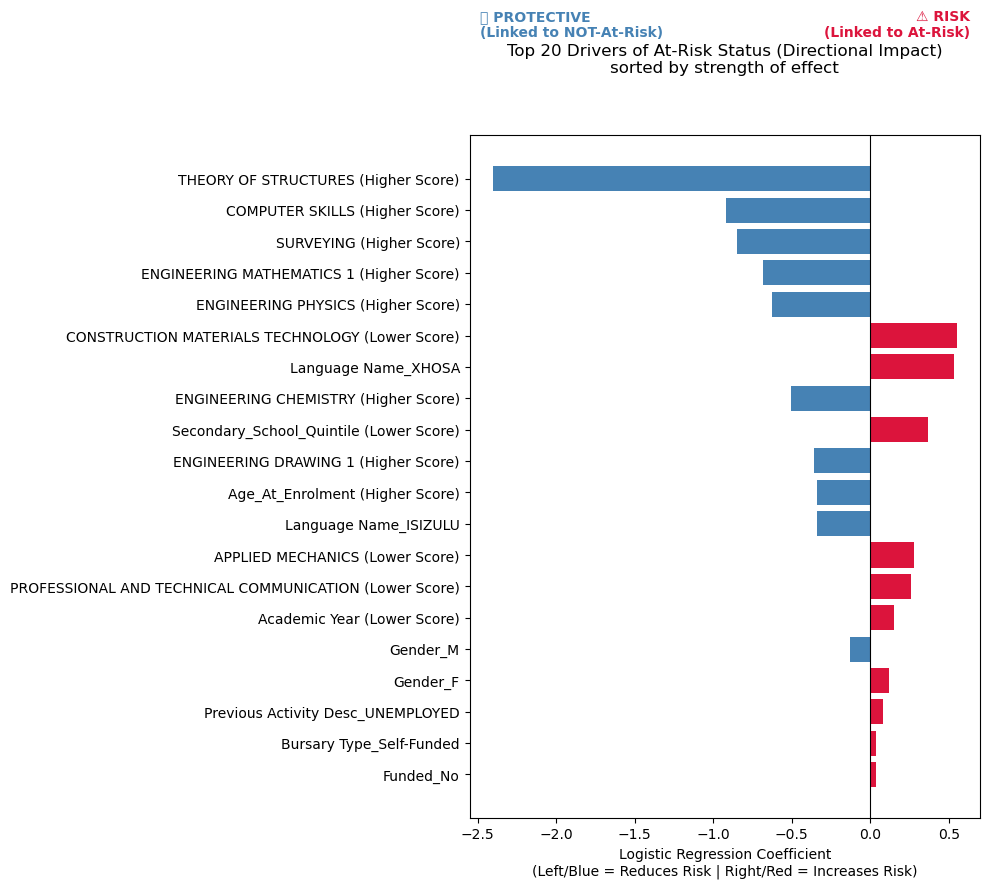

In [32]:
def clean_feature_label(feature_name):
    raw = feature_name.split("__", 1)[-1]  # strip "num__"/"cat__"
    is_numeric = any(feature_name.startswith(f"num__{col}") for col in numerical_features)
    return raw, is_numeric


plot_rows = []
for _, row in coef_df.iterrows():
    label, is_numeric = clean_feature_label(row["Feature"])
    if is_numeric:
        # Which direction of the raw mark is protective - not simply the
        # coefficient's sign, since a POSITIVE coefficient means a HIGHER
        # mark increases risk, i.e. a LOWER mark is the protective one.
        tag = "(Higher Score)" if row["Coefficient"] < 0 else "(Lower Score)"
        label = f"{label} {tag}"
    plot_rows.append({"Label": label, "Coefficient": row["Coefficient"]})

plot_df = pd.DataFrame(plot_rows)

# THE FIX: sort by MAGNITUDE (largest driver first), not raw signed value -
# consistent with every other importance chart in this notebook.
plot_df = plot_df.reindex(plot_df["Coefficient"].abs().sort_values(ascending=False).index)
top20 = plot_df.head(20)

colors = ["crimson" if v > 0 else "steelblue" for v in top20["Coefficient"]]

plt.figure(figsize=(10, 9))
plt.barh(top20["Label"], top20["Coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.gca().invert_yaxis()

plt.xlabel("Logistic Regression Coefficient\n"
           "(Left/Blue = Reduces Risk | Right/Red = Increases Risk)")
plt.title("Top 20 Drivers of At-Risk Status (Directional Impact)\n"
          "sorted by strength of effect", pad=45)  # <-- push title down, away from the headers

ax = plt.gca()
ax.text(0.02, 1.14, "🟦 PROTECTIVE\n(Linked to NOT-At-Risk)",
        transform=ax.transAxes, color="steelblue", fontweight="bold",
        va="bottom", ha="left")
ax.text(0.98, 1.14, "⚠ RISK\n(Linked to At-Risk)",
        transform=ax.transAxes, color="crimson", fontweight="bold",
        va="bottom", ha="right")

plt.tight_layout()
plt.show()

### Logistic Regression — feature importance (aggregated |coefficient|)

Logistic Regression has no `feature_importances_` attribute the way Random Forest does, so
the closest equivalent is the **magnitude** of each coefficient — how strongly a feature
pulls the prediction, regardless of direction. The cell below aggregates `abs(coefficient)`
across one-hot-encoded dummies back to each original variable (same approach used for the
Random Forest importance chart above), so the two charts can be compared side by side.

Note this isn't on the same numerical scale as Random Forest's Gini-based importance — only
the *within-model ranking* is comparable, not the raw values across models.

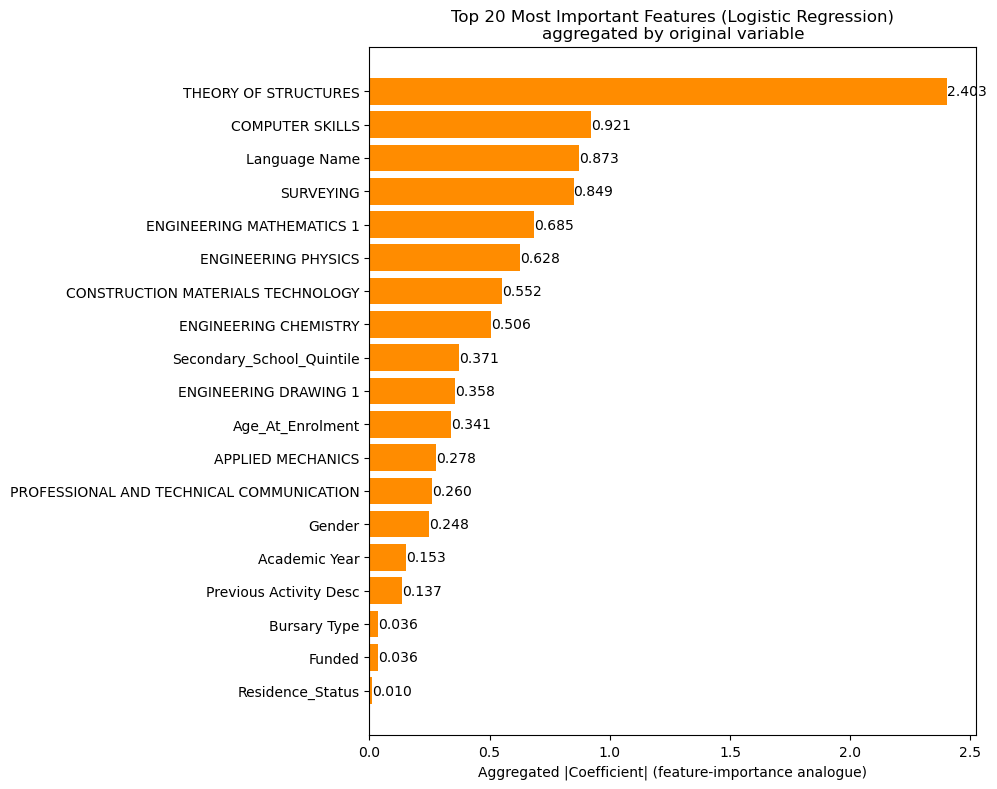

,Feature,Importance
0,THEORY OF STRUCTURES,2.403015
1,COMPUTER SKILLS,0.921142
6,Language Name,0.872898
2,SURVEYING,0.849083
3,ENGINEERING MATHEMATICS 1,0.684649
4,ENGINEERING PHYSICS,0.627520
5,CONSTRUCTION MATERIALS TECHNOLOGY,0.551595
7,ENGINEERING CHEMISTRY,0.506080
8,Secondary_School_Quintile,0.371123
9,ENGINEERING DRAWING 1,0.357643


In [33]:
def lr_base_feature_name(name):
    name = name.split("__", 1)[-1]          # strip the "num__"/"cat__" prefix
    for col in categorical_features:
        if name.startswith(col + "_"):      # strip the one-hot category suffix
            return col
    return name

lr_agg = {}
for feat, coef in zip(coef_df["Feature"], coef_df["Coefficient"]):
    base = lr_base_feature_name(feat)
    lr_agg[base] = lr_agg.get(base, 0) + abs(coef)

lr_importance_agg_df = pd.DataFrame(
    {"Feature": list(lr_agg.keys()), "Importance": list(lr_agg.values())}
).sort_values("Importance", ascending=False)

lr_top20_agg = lr_importance_agg_df.head(20)

plt.figure(figsize=(10, 8))
plt.barh(lr_top20_agg["Feature"], lr_top20_agg["Importance"], color="darkorange")
plt.xlabel("Aggregated |Coefficient| (feature-importance analogue)")
plt.title("Top 20 Most Important Features (Logistic Regression)\naggregated by original variable")
plt.gca().invert_yaxis()

for i, value in enumerate(lr_top20_agg["Importance"]):
    plt.text(value, i, f"{value:.3f}", va="center")

plt.tight_layout()
plt.show()

lr_importance_agg_df.head(20)

In [34]:
key_features = [
    "THEORY OF STRUCTURES", "COMPUTER SKILLS", "SURVEYING",
    "ENGINEERING MATHEMATICS 1", "CONSTRUCTION MATERIALS TECHNOLOGY",
    "Age_At_Enrolment"
]

coef_table_df = coef_df[
    coef_df["Feature"].str.contains("|".join(key_features), case=False)
][["Feature", "Coefficient", "Odds Ratio", "Direction"]].round(3)

# Tidy the "num__"/"cat__" prefix for the write-up
coef_table_df["Feature"] = coef_table_df["Feature"].str.replace(
    r"^(num__|cat__)", "", regex=True
)
coef_table_df

,Feature,Coefficient,Odds Ratio,Direction
10,THEORY OF STRUCTURES,-2.403,0.090,Associated with Not-At-Risk
2,COMPUTER SKILLS,-0.921,0.398,Associated with Not-At-Risk
9,SURVEYING,-0.849,0.428,Associated with Not-At-Risk
6,ENGINEERING MATHEMATICS 1,-0.685,0.504,Associated with Not-At-Risk
3,CONSTRUCTION MATERIALS TECHNOLOGY,0.552,1.736,Associated with At-Risk
11,Age_At_Enrolment,-0.341,0.711,Associated with Not-At-Risk


In [35]:
# Example the supervisor/reader will likely ask about first: Age_At_Enrolment.
print(coef_df[coef_df["Feature"].str.contains("Age_At_Enrolment")].to_string(index=False))

              Feature  Coefficient  Odds Ratio                   Direction
num__Age_At_Enrolment    -0.341165    0.710942 Associated with Not-At-Risk


### Random Forest direction (SHAP)

In [36]:
!pip install shap

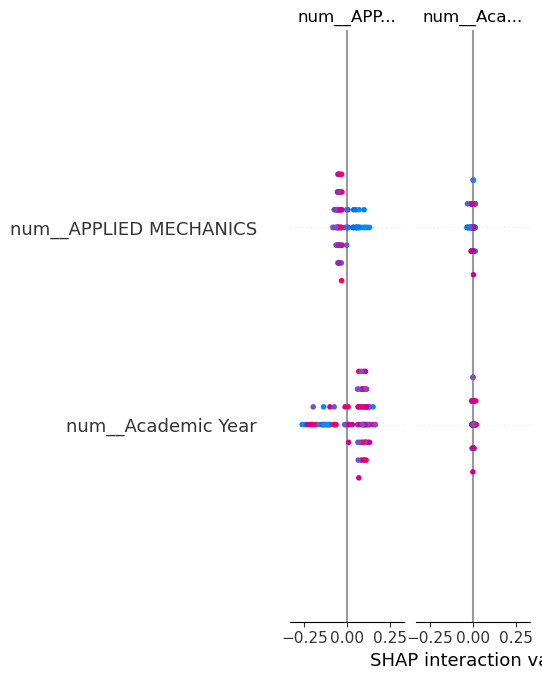

In [37]:
# SHAP gives the Random Forest the same kind of directional reading the
# Logistic Regression coefficients give above: for every prediction, which
# way did each feature push it, and by how much.
# Requires: pip install shap
try:
    import shap

    rf_clf = rf_model.named_steps["classifier"]
    X_test_transformed = transform_up_to_classifier(rf_model, X_test)
    rf_feature_names = get_final_feature_names(rf_model)

    explainer = shap.TreeExplainer(rf_clf)
    shap_values = explainer.shap_values(X_test_transformed)
    # Newer shap versions return an Explanation object or a 3-D array
    # (samples, features, classes); older ones return a list [class0, class1].
    if isinstance(shap_values, list):
        sv = shap_values[1]
    elif hasattr(shap_values, "values") and shap_values.values.ndim == 3:
        sv = shap_values.values[:, :, 1]
    else:
        sv = shap_values

    shap.summary_plot(
        sv, X_test_transformed, feature_names=rf_feature_names, show=True
    )
    # Positive SHAP value = pushes THIS prediction toward At-Risk (class 1).
    # Point colour = the feature's own value (red = high, blue = low), so
    # e.g. a cluster of red dots on the positive side for Age_At_Enrolment
    # would mean "older students are pushed toward At-Risk".
except ImportError:
    print("SHAP is not installed in this environment.")
    print("Run: pip install shap")
    print("Then re-run this cell to see which way (not just how much) each")
    print("feature pushes the Random Forest's predictions.")

### Permutation importance — one comparable measure for both models

Random Forest's Gini importance and Logistic Regression's `|coefficient|`
(used earlier) are on different scales and aren't directly comparable.
Permutation importance sidesteps that: it shuffles each ORIGINAL column
(not each one-hot dummy) on the held-out test set and measures how much
ROC AUC drops — the same measure, computed the same way, for both models.

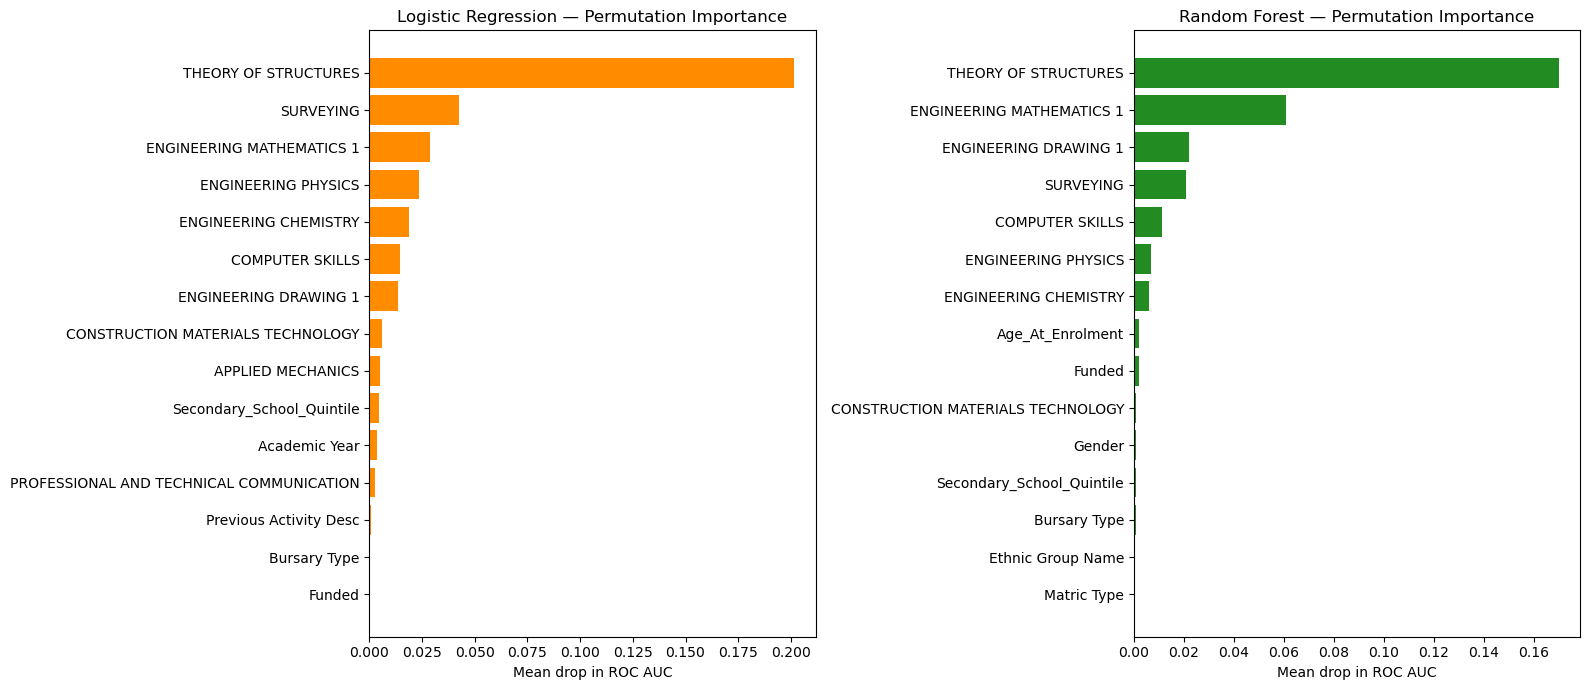

,Feature,Importance (mean ROC AUC drop),Std,Model
10,THEORY OF STRUCTURES,0.201675,0.043214,Logistic Regression
9,SURVEYING,0.042710,0.013840,Logistic Regression
6,ENGINEERING MATHEMATICS 1,0.028674,0.011496,Logistic Regression
7,ENGINEERING PHYSICS,0.023427,0.013432,Logistic Regression
4,ENGINEERING CHEMISTRY,0.018577,0.007327,Logistic Regression
2,COMPUTER SKILLS,0.014638,0.016849,Logistic Regression
5,ENGINEERING DRAWING 1,0.013477,0.005236,Logistic Regression
3,CONSTRUCTION MATERIALS TECHNOLOGY,0.006099,0.009210,Logistic Regression
1,APPLIED MECHANICS,0.004909,0.004407,Logistic Regression
20,Secondary_School_Quintile,0.004674,0.006718,Logistic Regression


In [38]:
from sklearn.inspection import permutation_importance


def perm_importance_table(fitted_pipeline, X, y, model_name, n_repeats=30):
    result = permutation_importance(
        fitted_pipeline, X, y,
        scoring="roc_auc",
        n_repeats=n_repeats,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    return pd.DataFrame({
        "Feature": X.columns,
        "Importance (mean ROC AUC drop)": result.importances_mean,
        "Std": result.importances_std,
        "Model": model_name
    }).sort_values("Importance (mean ROC AUC drop)", ascending=False)


lr_perm_df = perm_importance_table(logistic_model, X_test, y_test, "Logistic Regression")
rf_perm_df = perm_importance_table(rf_model, X_test, y_test, "Random Forest")

top15_lr = lr_perm_df.head(15)
top15_rf = rf_perm_df.head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].barh(top15_lr["Feature"], top15_lr["Importance (mean ROC AUC drop)"], color="darkorange")
axes[0].invert_yaxis()
axes[0].set_title("Logistic Regression — Permutation Importance")
axes[0].set_xlabel("Mean drop in ROC AUC")

axes[1].barh(top15_rf["Feature"], top15_rf["Importance (mean ROC AUC drop)"], color="forestgreen")
axes[1].invert_yaxis()
axes[1].set_title("Random Forest — Permutation Importance")
axes[1].set_xlabel("Mean drop in ROC AUC")

plt.tight_layout()
plt.show()

lr_perm_df.head(10)

### Threshold tuning - chosen on the training set, applied to the test set once

The original version chose the decision threshold by scanning precision/recall
directly against the test set, then reported metrics on that same test set at
the chosen threshold - meaning the threshold was implicitly fit to the test
data. Below, the threshold is instead chosen from out-of-fold predicted
probabilities on the *training* set (`cross_val_predict`), and only applied
to the test set once, for a single, honest final read.

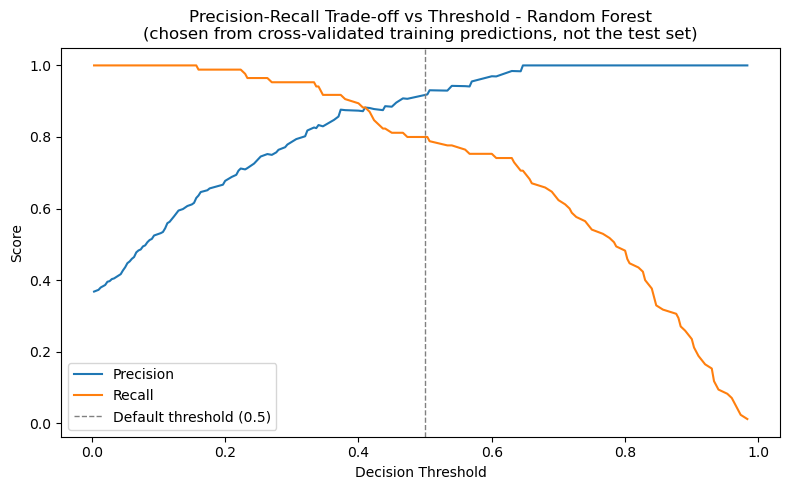

Lowest threshold reaching >= 85% recall (from training-set CV): 0.420
  -> CV Recall: 0.859, CV Precision: 0.880

Classification report on the TEST set at the CV-chosen threshold:
              precision    recall  f1-score   support

 Not At Risk       0.92      0.94      0.93        63
     At Risk       0.89      0.86      0.87        36

    accuracy                           0.91        99
   macro avg       0.90      0.90      0.90        99
weighted avg       0.91      0.91      0.91        99



In [39]:
# Out-of-fold predicted probabilities on the TRAINING set, so the threshold
# itself is never fit on the test set.
train_oof_prob = cross_val_predict(
    rf_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_train, train_oof_prob)

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions[:-1], label="Precision")
plt.plot(thresholds, recalls[:-1], label="Recall")
plt.axvline(0.5, color="gray", linestyle="--", linewidth=1, label="Default threshold (0.5)")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision-Recall Trade-off vs Threshold - Random Forest\n"
          "(chosen from cross-validated training predictions, not the test set)")
plt.legend()
plt.tight_layout()
plt.show()

target_recall = 0.85
valid = [
    (t, p, r) for p, r, t in zip(precisions[:-1], recalls[:-1], thresholds)
    if r >= target_recall
]

if valid:
    best_threshold, best_precision, best_recall = max(valid, key=lambda x: x[0])
    print(f"Lowest threshold reaching >= {target_recall:.0%} recall (from training-set CV): {best_threshold:.3f}")
    print(f"  -> CV Recall: {best_recall:.3f}, CV Precision: {best_precision:.3f}")

    # Apply the CV-chosen threshold to the held-out test set exactly once,
    # for the final report.
    pred_tuned = (prob >= best_threshold).astype(int)
    print("\nClassification report on the TEST set at the CV-chosen threshold:")
    print(classification_report(y_test, pred_tuned, target_names=["Not At Risk", "At Risk"]))
else:
    print(f"No threshold in the training-set CV predictions reaches {target_recall:.0%} recall.")

In [40]:
threshold_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (At Risk)", "Recall (At Risk)", "F1-score (At Risk)"],
    "Default threshold (0.5)": [
        accuracy_score(y_test, pred),
        precision_score(y_test, pred),
        recall_score(y_test, pred),
        f1_score(y_test, pred)
    ],
    f"Tuned threshold ({best_threshold:.3f})": [
        accuracy_score(y_test, pred_tuned),
        precision_score(y_test, pred_tuned),
        recall_score(y_test, pred_tuned),
        f1_score(y_test, pred_tuned)
    ]
}).round(3)

threshold_df

,Metric,Default threshold (0.5),Tuned threshold (0.420)
0,Accuracy,0.879,0.909
1,Precision (At Risk),0.962,0.886
2,Recall (At Risk),0.694,0.861
3,F1-score (At Risk),0.806,0.873
